# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** *(the Breast Cancer Wisconsin's objective is to predict whether the breast tumor is maligant or benign based on 30 numeric features from degitized images fine-needle aspirates. The type of learning is supervised binary because of the given example of both malignant and benign. False negative is the most costly error because predicting a malignant as benign can delay the diagnosis and treatment for the patient. The success will be judged by accuracy, precision, recall, and F1 ensuring that it can identify malignant tumors )*

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import ( RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).

> *Using your own data?* Only this cell changes. For an ARFF file use `scipy.io.arff.loadarff`, and keep the rest of the workbook as is.

> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [ ]:
# TODO: load the dataset and copy its DataFrame into df
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
...
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [ ]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows

print("Dataset Shape:", df.shape)

print("\nCounts of Each Data Type:")
print(df.dtypes.value_counts())

print("\nFirst 5 Rows:")
display(df.head(5))


Dataset Shape: (569, 31)

Counts of Each Data Type:
float64    30
int64       1
Name: count, dtype: int64

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [ ]:
# TODO: class counts and percentages

class_counts = df["target"].value_counts().sort_index()

class_percentages = df["target"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

class_summary.index = class_summary.index.map({
    0: "Malignant",
    1: "Benign"
})

print("Class Counts and Percentages:")
display(class_summary)


Class Counts and Percentages:


,Count,Percentage (%)
target,,
Malignant,212,37.26
Benign,357,62.74


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [ ]:
# TODO: describe().T, then the 10 largest skewness values

print("Statistics Summary:")
display(df.describe().T)

skewness = df.drop(columns=["target"]).skew()

print("\nTop 10 Most Skewed Features:")
top_10_skewed = skewness.reindex(
    skewness.abs().sort_values(ascending=False).head(10).index
)

display(top_10_skewed.to_frame(name="Skewness"))


Statistics Summary:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



Top 10 Most Skewed Features:


,Skewness
area error,5.447186
concavity error,5.110463
fractal dimension error,3.923969
perimeter error,3.443615
radius error,3.088612
smoothness error,2.314450
symmetry error,2.195133
compactness error,1.902221
worst area,1.859373
worst fractal dimension,1.662579


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [ ]:
# TODO: correlation with target, sorted

target_corr = df.corr(numeric_only=True)["target"].drop("target")

target_corr_sorted = target_corr.sort_values()

print("5 Most Negative Correlations with Target:")
display(target_corr_sorted.head(5).to_frame(name="Correlation"))

print("\n5 Most Positive Correlations with Target:")
display(target_corr_sorted.tail(5).sort_values(ascending=False).to_frame(name="Correlation"))


5 Most Negative Correlations with Target:


,Correlation
worst concave points,-0.793566
worst perimeter,-0.782914
mean concave points,-0.776614
worst radius,-0.776454
mean perimeter,-0.742636



5 Most Positive Correlations with Target:


,Correlation
smoothness error,0.067016
mean fractal dimension,0.012838
texture error,0.008303
symmetry error,0.006522
fractal dimension error,-0.077972


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** *(The class proportions show that there are more benign cases than malignant cases in the dataset. Because of this, accuracy alone may not be enough to evaluate the model, so we should also look at recall, precision, and F1-score, especially recall to avoid missing malignant cases. The skewness shows that some features have uneven distributions, so we may need to use transformations to make the data more balanced and help the model perform better.)*

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

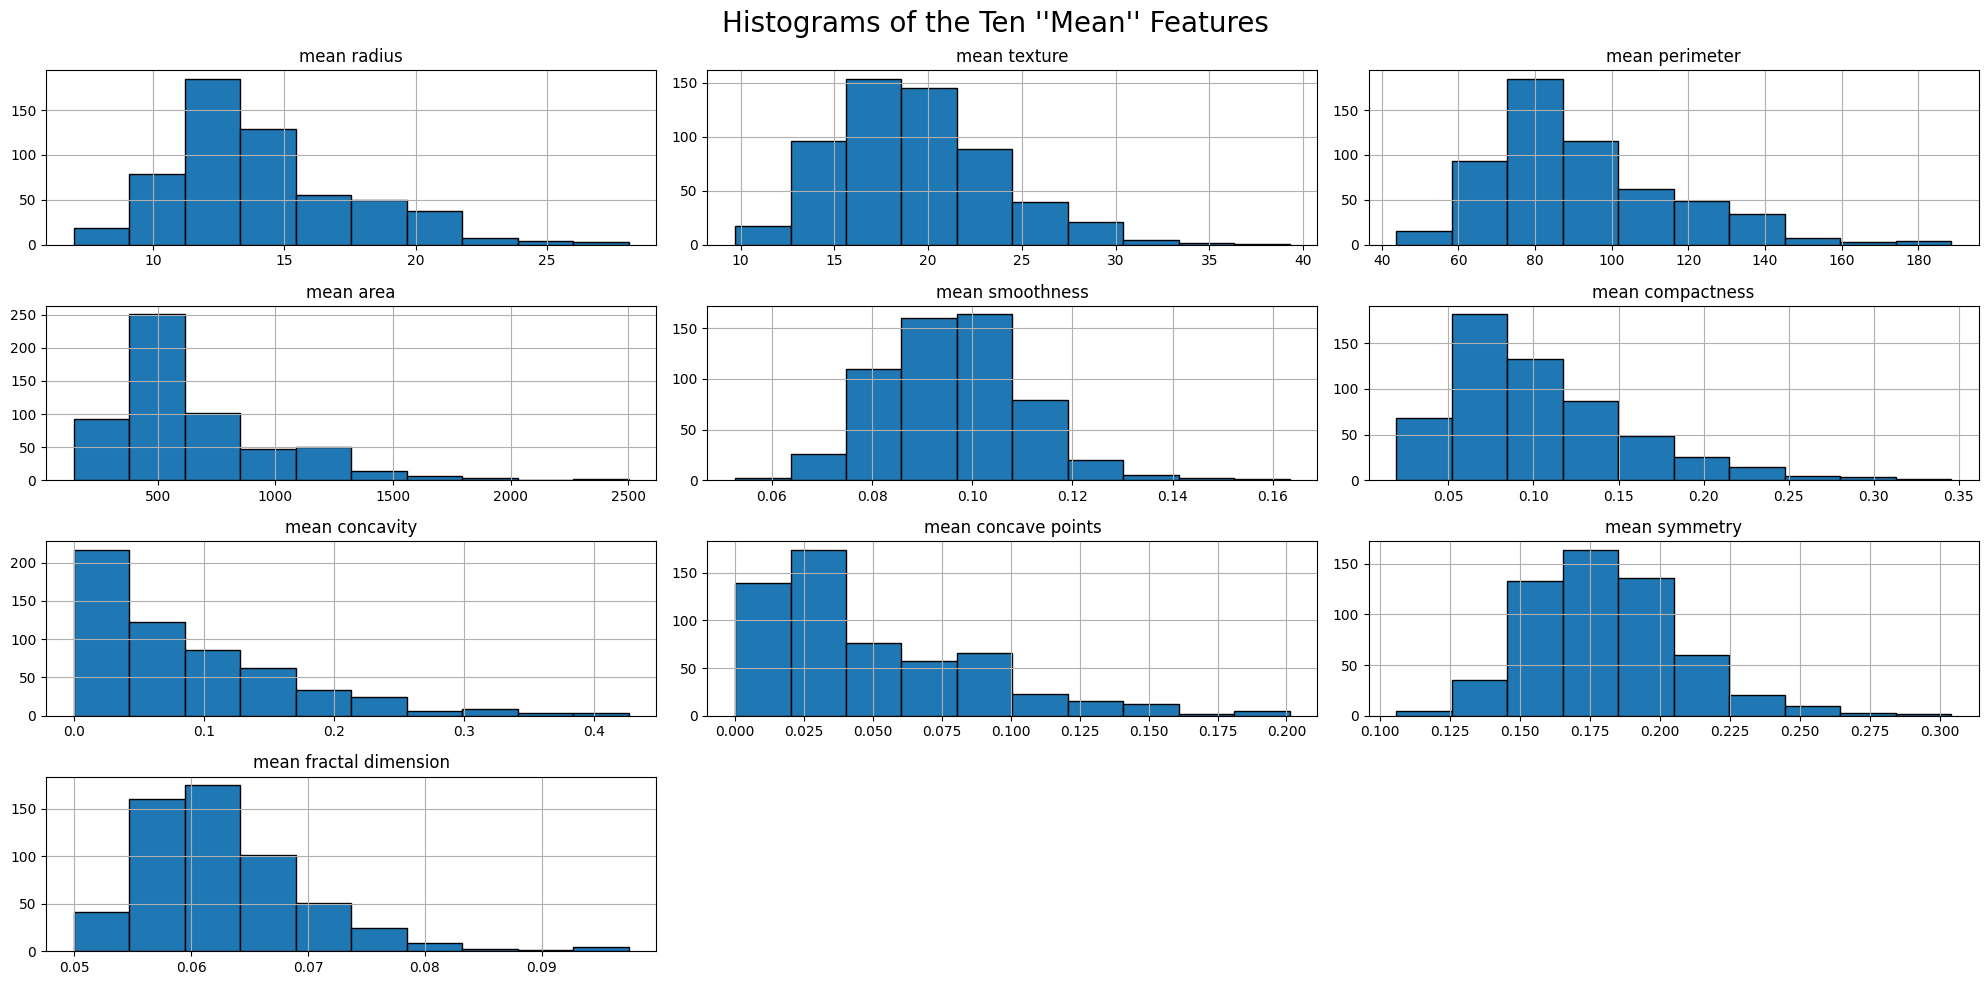

In [ ]:
# TODO: histograms of the ten "mean" features (hint: df.filter(like="mean").hist)

df.filter(like="mean").hist(figsize=(20, 10), bins=10, edgecolor="black")
plt.suptitle("Histograms of the Ten ''Mean'' Features", fontsize=20)
plt.tight_layout()
plt.show()


**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

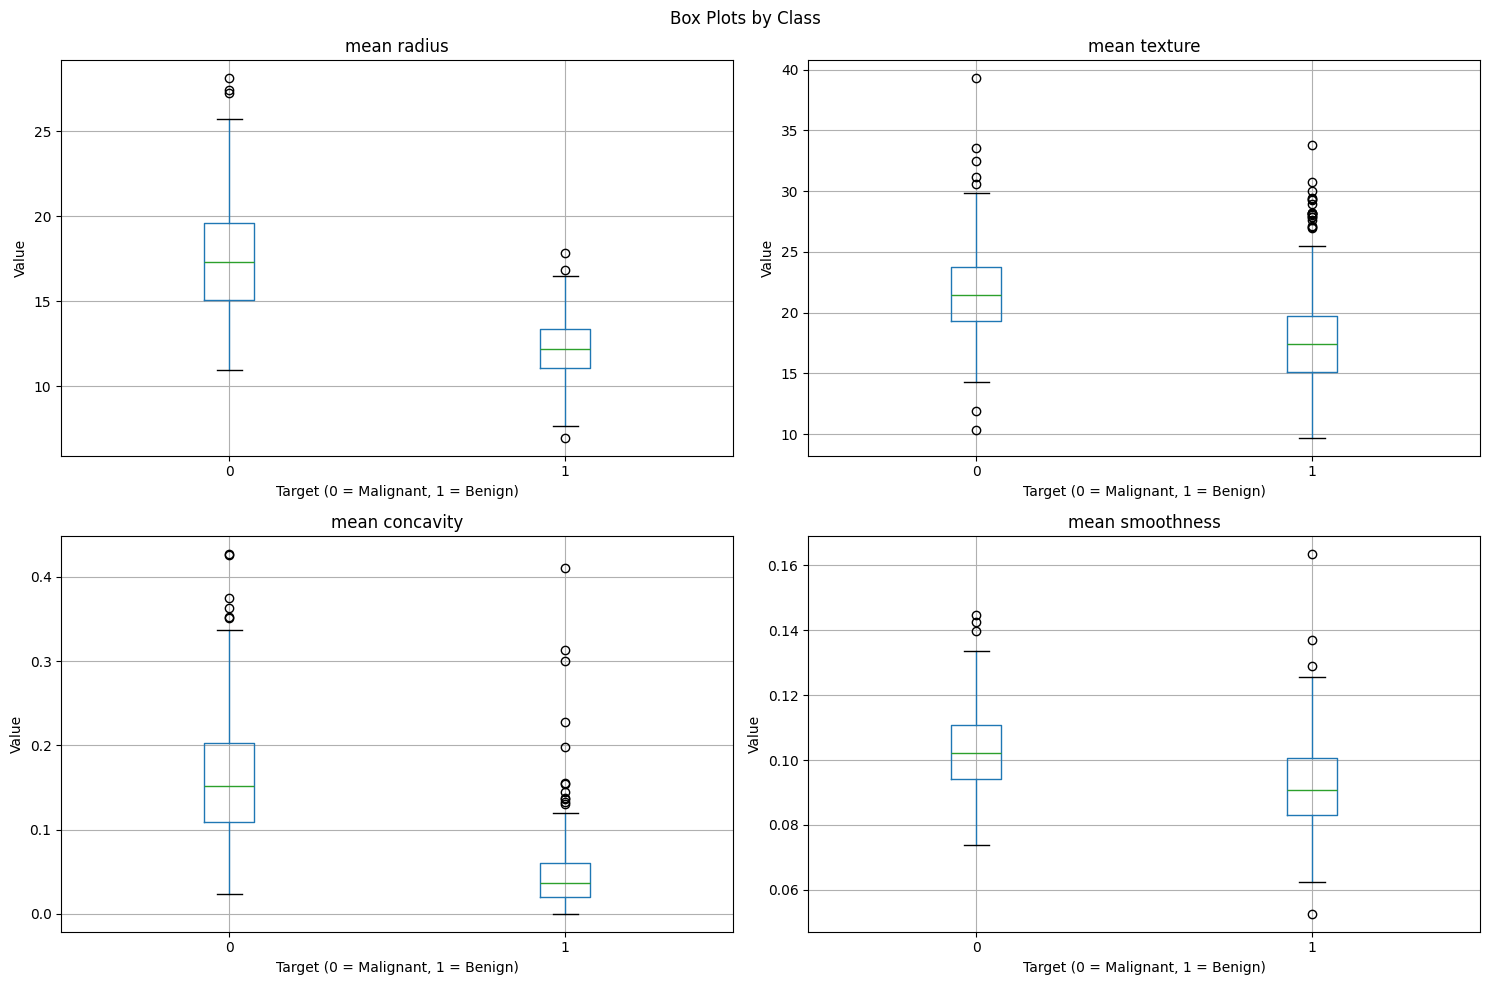

In [ ]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, feature in zip(axes.flatten(), features):
    df.boxplot(column=feature, by="target", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Target (0 = Malignant, 1 = Benign)")
    ax.set_ylabel("Value")

plt.suptitle("Box Plots by Class")
plt.tight_layout()
plt.show()


**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

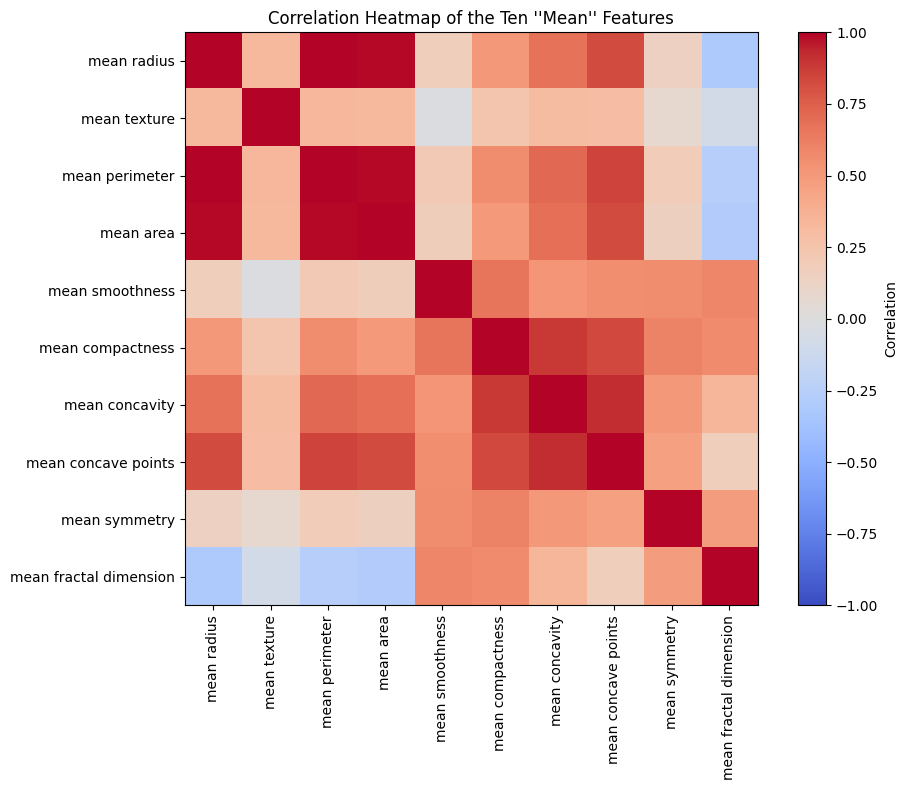

In [ ]:
# TODO: correlation matrix of the "mean" features drawn with imshow

mean_features = df.filter(like="mean")

corr_matrix = mean_features.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title("Correlation Heatmap of the Ten ''Mean'' Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

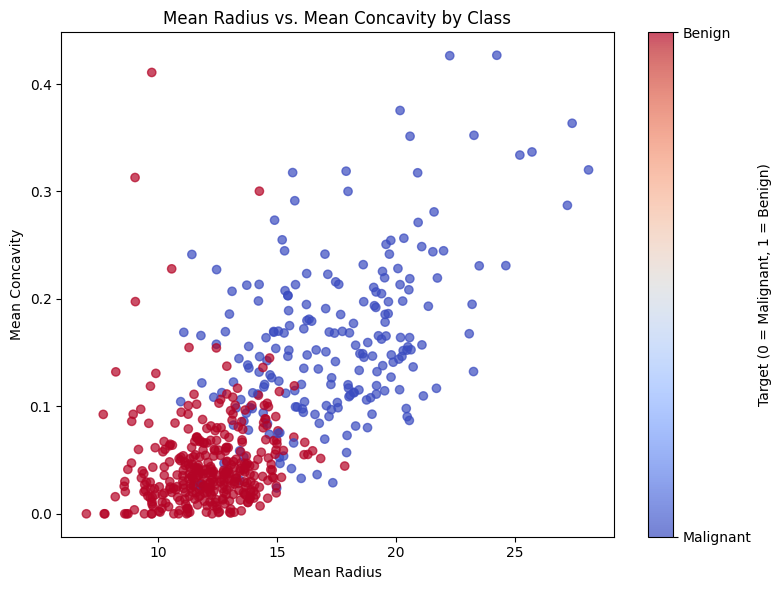

In [ ]:
# TODO: coloured scatter plot with axis labels and a colourbar

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    df["mean radius"],
    df["mean concavity"],
    c=df["target"],
    cmap="coolwarm",
    alpha=0.7
)

plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity by Class")

cbar = plt.colorbar(scatter)
cbar.set_label("Target (0 = Malignant, 1 = Benign)")
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Malignant", "Benign"])

plt.tight_layout()
plt.show()


✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** *(mean radius, mean perimeter, and mean area are kind of redundant because they all describe the size of the tumor and are strongly related. Mean radius and mean concavity seem to separate malignant and benign tumors better because malignant tumors usually have bigger sizes and higher concavity. However, some of the values still overlap between the two classes.)*

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [ ]:
# TODO: total missing values and duplicated rows
print("Total Missing Values:", df.isnull().sum().sum())

print("Total Duplicate Rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total Missing Values: 0
Total Duplicate Rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [ ]:
# TODO: IQR outlier count per feature

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_counts = ((X < lower_bound) | (X > upper_bound)).sum()

top_10_outliers = outlier_counts.sort_values(ascending=False).head(10)

print("Top 10 Features with the Most Outliers:")
display(top_10_outliers.to_frame(name="Outlier Count"))


Top 10 Features with the Most Outliers:


,Outlier Count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** *(I would not delete the outliers because they might be important data about the tumors, especially the malignant ones. Removing them could make us lose useful information and affect the model's accuracy.)*

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [ ]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95

corr_matrix = X.corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.95)
]

print("features that has greater than 0.95 on Absolute Correlation:")
print(high_corr_features)


features that has greater than 0.95 on Absolute Correlation:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [ ]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores

selector = SelectKBest(score_func=f_classif, k=10)
selector.fit(X, y)

feature_scores = pd.Series(
    selector.scores_,
    index=X.columns
).sort_values(ascending=False)

print("Top 10 Features Ranked by F-score:")
display(feature_scores.head(10).to_frame(name="F-score"))


Top 10 Features Ranked by F-score:


,F-score
worst concave points,964.385393
worst perimeter,897.944219
mean concave points,861.676020
worst radius,860.781707
mean perimeter,697.235272
worst area,661.600206
mean radius,646.981021
mean area,573.060747
mean concavity,533.793126
worst concavity,436.691939


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [ ]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

rfe = RFE(
    estimator=LogisticRegression(max_iter=10000, random_state=7),
    n_features_to_select=10
)

rfe.fit(X_scaled, y)

rfe_features = X.columns[rfe.support_].tolist()

print("10 Features Selected by RFE:")
print(rfe_features)


10 Features Selected by RFE:
['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

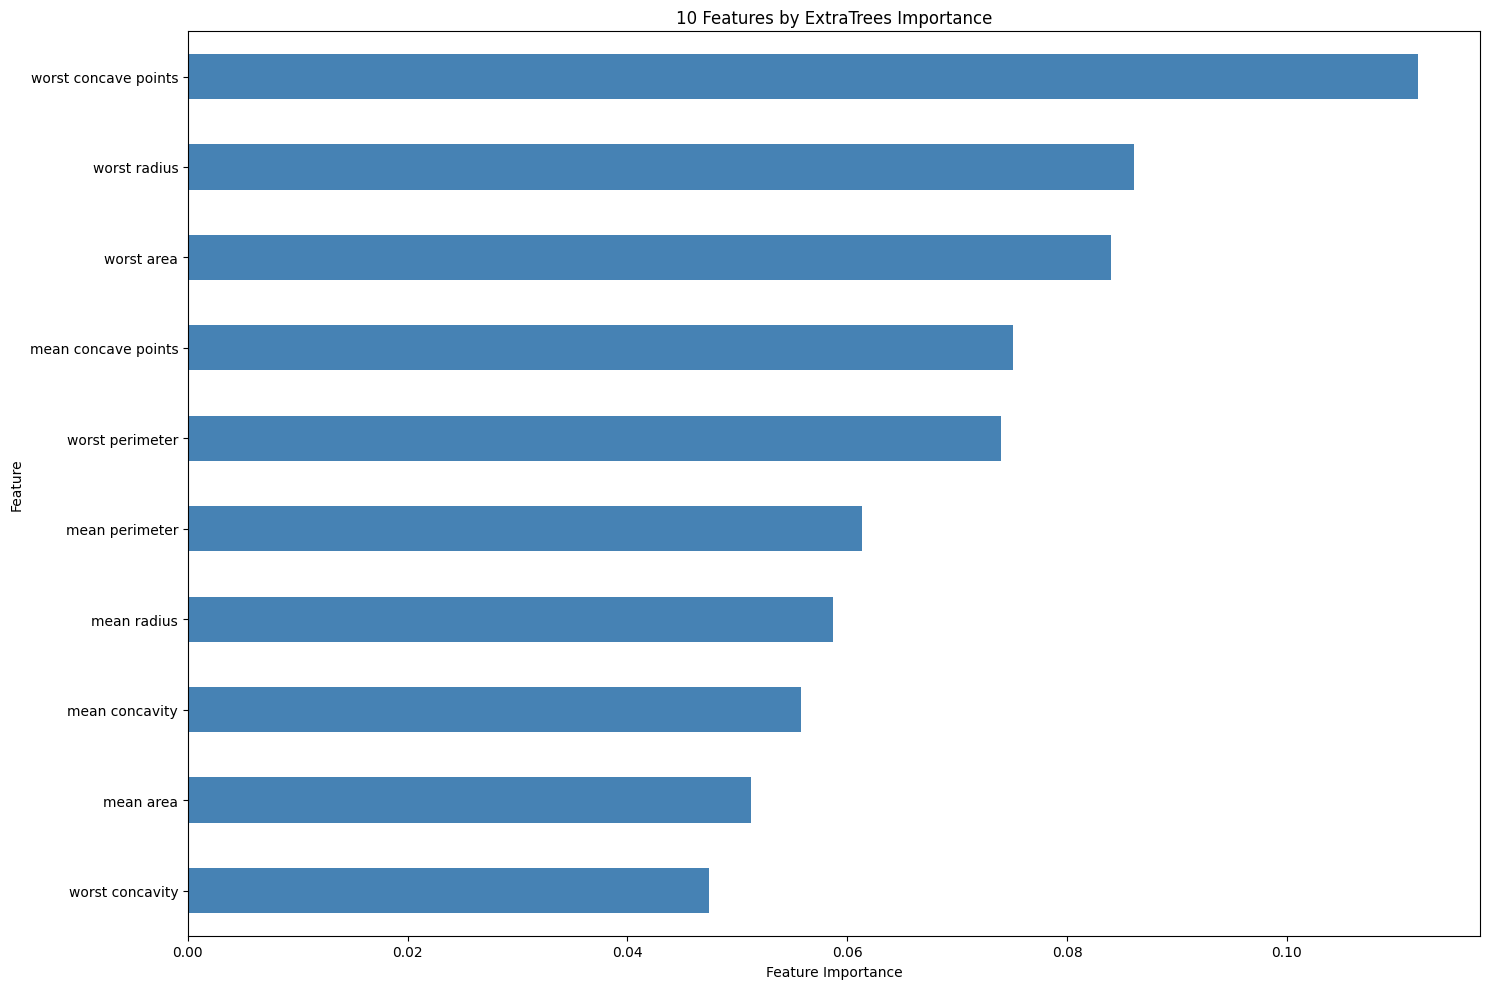

10 Features by ExtraTrees:


,Importance
worst concave points,0.111981
worst radius,0.086108
worst area,0.083990
mean concave points,0.075045
worst perimeter,0.074022
mean perimeter,0.061303
mean radius,0.058711
mean concavity,0.055757
mean area,0.051197
worst concavity,0.047384


In [ ]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10

et = ExtraTreesClassifier(n_estimators=200, random_state=7)
et.fit(X, y)

imp = pd.Series(
    et.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

top10_imp = imp.head(10)

plt.figure(figsize=(15, 10))
top10_imp.sort_values().plot(kind="barh", color="steelblue")

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("10 Features by ExtraTrees Importance")
plt.tight_layout()
plt.show()

print("10 Features by ExtraTrees:")
display(top10_imp.to_frame(name="Importance"))


**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [ ]:
# TODO: vote across the three methods

kbest_features = feature_scores.head(10).index.tolist()

et_features = imp.head(10).index.tolist()

feature_votes = pd.Series(0, index=X.columns)

for feature in kbest_features:
    feature_votes[feature] += 1

for feature in rfe_features:
    feature_votes[feature] += 1

for feature in et_features:
    feature_votes[feature] += 1

selected = feature_votes[feature_votes >= 2].index.tolist()

print("Selected Features:")
print(selected)

print("\nNumber of Selected Features:", len(selected))

display(
    feature_votes.sort_values(ascending=False)
    .to_frame(name="Number of Votes")
)


Selected Features:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']

Number of Selected Features: 10


,Number of Votes
mean concave points,3
worst concavity,3
worst perimeter,3
worst area,3
worst concave points,3
worst radius,3
mean area,2
mean perimeter,2
mean concavity,2
mean radius,2


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [ ]:
# TODO: train_test_split with stratify=y

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=7,
    stratify=y
)

print("Training and testing set shapes:")
print(X_train.shape, X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index(),y_test.value_counts(normalize=True).sort_index())

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training and testing set shapes:
(455, 30) (114, 30)

Training class proportions:
target
0    0.373626
1    0.626374
Name: proportion, dtype: float64 target
0    0.368421
1    0.631579
Name: proportion, dtype: float64

Testing class proportions:
target
0    0.368421
1    0.631579
Name: proportion, dtype: float64


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [ ]:
# TODO: fit both scalers on X_train and print the verifying statistics

standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X_train_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_train_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

first_four = X_train.columns[:4]

print("Mean and Standard Deviation")
display(pd.DataFrame({
    "Mean": X_train_standard[first_four].mean(),
    "Standard Deviation": X_train_standard[first_four].std(ddof=0)
}).round(4))

print("\nMinimum and Maximum")
display(pd.DataFrame({
    "Minimum": X_train_minmax[first_four].min(),
    "Maximum": X_train_minmax[first_four].max()
}).round(4))


Mean and Standard Deviation


,Mean,Standard Deviation
mean radius,-0.0,1.0
mean texture,-0.0,1.0
mean perimeter,-0.0,1.0
mean area,0.0,1.0



Minimum and Maximum


,Minimum,Maximum
mean radius,0.0,1.0
mean texture,0.0,1.0
mean perimeter,0.0,1.0
mean area,0.0,1.0


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [ ]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance

pca = PCA()
pca.fit(X_train_standard)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Principal components needed for 95% variance:",
      n_components_95)

print("Cumulative explained variance:",
      round(cumulative_variance[n_components_95 - 1], 4))


Principal components needed for 95% variance: 10
Cumulative explained variance: 0.956


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [ ]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(max_iter=10000, random_state=seed),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC(probability=True, random_state=seed)
}


def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [ ]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled

raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: scores.mean() for name, scores in raw_results.items()},
    "scaled": {name: scores.mean() for name, scores in scaled_results.items()}
})

print("Mean Cross-Validation Accuracy:")
display(summary.round(4))

Mean Cross-Validation Accuracy:


,raw,scaled
LR,0.9538,0.9823
LDA,0.9472,0.9472
KNN,0.9229,0.9649
CART,0.9276,0.9276
NB,0.9341,0.9320
SVM,0.8987,0.9758


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** *(KNN, SVM, and Logistic Regression usually benefit the most from scaling because they are affected by differences in feature ranges. Scaling puts the features on a similar scale, which helps these models make better predictions. Decision Trees and Naive Bayes usually benefit less from scaling because they are less sensitive to feature magnitudes.)*

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [ ]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results

selected_results = spot_check(
    models,
    X_train[selected],
    scale=True
)

selected_summary = pd.DataFrame({
    "All Features (Scaled)": {
        name: scores.mean()
        for name, scores in scaled_results.items()
    },
    "Selected Features (Scaled)": {
        name: scores.mean()
        for name, scores in selected_results.items()
    }
})

print("All Features vs Selected Features:")
display(selected_summary.round(4))

All Features vs Selected Features:


,All Features (Scaled),Selected Features (Scaled)
LR,0.9823,0.9604
LDA,0.9472,0.9430
KNN,0.9649,0.9428
CART,0.9276,0.9210
NB,0.9320,0.9517
SVM,0.9758,0.9539


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

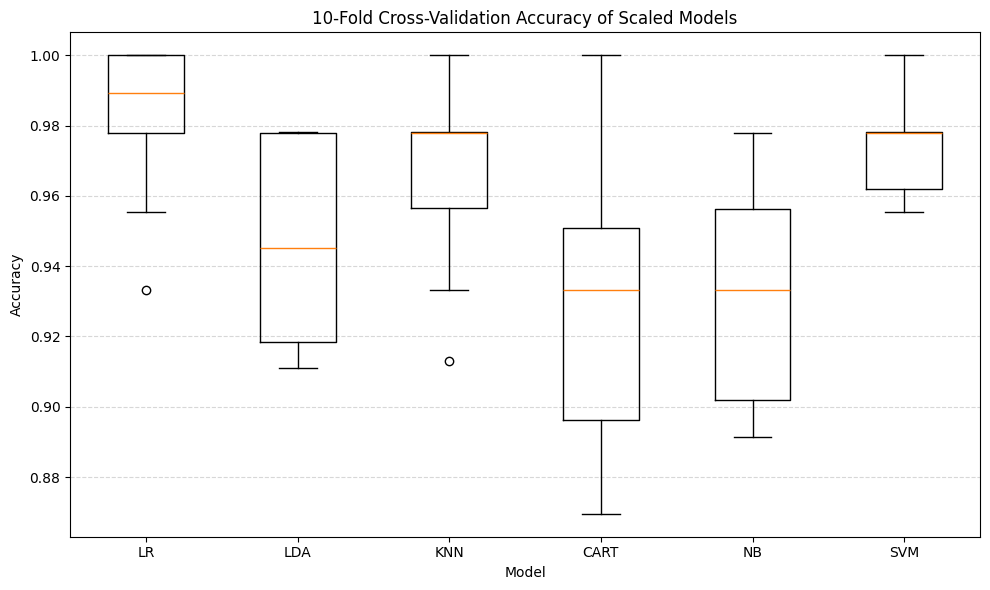

In [ ]:
# TODO: box plot of the 10 fold scores per model

score_data = [
    scaled_results[name]
    for name in models.keys()
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    score_data,
    tick_labels=list(models.keys())
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("10-Fold Cross-Validation Accuracy of Scaled Models")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [ ]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)

best_name = max(
    scaled_results,
    key=lambda name: scaled_results[name].mean()
)

best_model = models[best_name]

print("Best Scaled Model:", best_name)
print("Mean Accuracy:", round(scaled_results[best_name].mean(), 4))

best_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", best_model)
])

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "malignant_recall": make_scorer(
        recall_score,
        pos_label=0
    )
}

cv_results = cross_validate(
    best_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

evaluation_summary = pd.DataFrame({
    "Mean": {
        metric: cv_results[f"test_{metric}"].mean()
        for metric in scoring
    },
    "Standard Deviation": {
        metric: cv_results[f"test_{metric}"].std()
        for metric in scoring
    }
})

print("\nCross-Validation Results:")
display(evaluation_summary.round(4))

Best Scaled Model: LR
Mean Accuracy: 0.9823

Cross-Validation Results:


,Mean,Standard Deviation
accuracy,0.9823,0.0218
roc_auc,0.9922,0.0107
malignant_recall,0.9647,0.0471


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [ ]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]

svm_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC(probability=True, random_state=7))
])

svm_param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
print("Best SVM CV Accuracy:", round(svm_grid.best_score_, 4))

best_svm = svm_grid.best_estimator_


Best SVM Parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV Accuracy: 0.9802


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [ ]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]

knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV Accuracy:", round(knn_grid.best_score_, 4))

best_knn = knn_grid.best_estimator_


Best KNN Parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV Accuracy: 0.9693


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [ ]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier

ensembles = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=7
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=7
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=7
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=7
    )
}

ensemble_results = spot_check(
    ensembles, X_train, scale=False
)

voting_model = VotingClassifier(
    estimators=[
        ("svm", best_svm),
        ("knn", best_knn),
        ("rf", ensembles["Random Forest"])
    ],
    voting="hard"
)

voting_results = cross_val_score(
    voting_model,
    X_train,
    y_train,
    cv=kfold,
    scoring="accuracy",
    n_jobs=-1
)

print("Ensemble Mean Cross-Validation Accuracies:")
for name, scores in ensemble_results.items():
    print(f"{name}: {scores.mean():.4f}")

print(f"Voting Ensemble: {voting_results.mean():.4f}")


Ensemble Mean Cross-Validation Accuracies:
Random Forest: 0.9648
Extra Trees: 0.9714
Gradient Boosting: 0.9670
AdaBoost: 0.9626
Voting Ensemble: 0.9781


**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [ ]:
# TODO: leaderboard Series

svm_scores = cross_val_score(
    best_svm, X_train, y_train,
    cv=kfold, scoring="accuracy", n_jobs=-1
)

knn_scores = cross_val_score(
    best_knn, X_train, y_train,
    cv=kfold, scoring="accuracy", n_jobs=-1
)

leaderboard_scores = {
    "Tuned SVM": svm_scores.mean(),
    "Tuned KNN": knn_scores.mean(),
    "Random Forest": ensemble_results["Random Forest"].mean(),
    "Extra Trees": ensemble_results["Extra Trees"].mean(),
    "Gradient Boosting": ensemble_results["Gradient Boosting"].mean(),
    "AdaBoost": ensemble_results["AdaBoost"].mean(),
    "Voting Ensemble": voting_results.mean()
}

leaderboard = pd.Series(
    leaderboard_scores,
    name="Mean CV Accuracy"
).sort_values(ascending=False)

print("Model Leaderboard:")
display(leaderboard.to_frame().round(4))


Model Leaderboard:


,Mean CV Accuracy
Tuned SVM,0.9802
Voting Ensemble,0.9781
Extra Trees,0.9714
Tuned KNN,0.9693
Gradient Boosting,0.9670
Random Forest,0.9648
AdaBoost,0.9626


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Winning Model: Tuned SVM
Test Accuracy: 0.9649

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



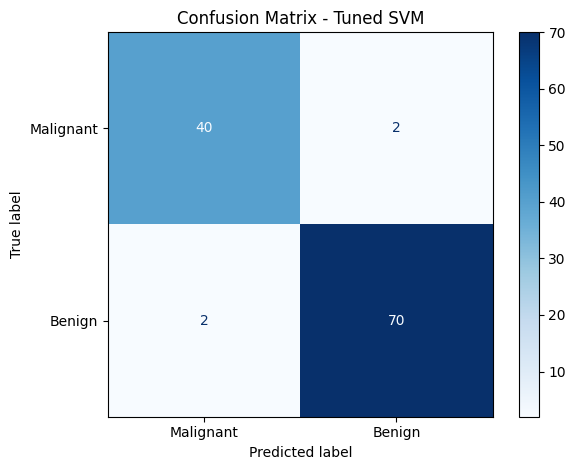

In [ ]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix

winner_name = leaderboard.index[0]

candidate_models = {
    "Tuned SVM": best_svm,
    "Tuned KNN": best_knn,
    "Random Forest": ensembles["Random Forest"],
    "Extra Trees": ensembles["Extra Trees"],
    "Gradient Boosting": ensembles["Gradient Boosting"],
    "AdaBoost": ensembles["AdaBoost"],
    "Voting Ensemble": voting_model
}

winner = candidate_models[winner_name]

winner.fit(X_train, y_train)

y_pred = winner.predict(X_test)

print("Winning Model:", winner_name)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Malignant", "Benign"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {winner_name}")
plt.tight_layout()
plt.show()


**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [ ]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test

import joblib
import numpy as np

joblib.dump(winner, "breast_cancer_model.joblib")

print("Model saved successfully.")

loaded_model = joblib.load("breast_cancer_model.joblib")

original_predictions = winner.predict(X_test.iloc[:5])
loaded_predictions = loaded_model.predict(X_test.iloc[:5])

print("\nOriginal Predictions:", original_predictions)
print("Reloaded Predictions:", loaded_predictions)
print("Actual Labels:", y_test.iloc[:5].to_numpy())

print(
    "\nPredictions Match:",
    np.array_equal(original_predictions, loaded_predictions)
)


Model saved successfully.

Original Predictions: [0 0 1 0 1]
Reloaded Predictions: [0 0 1 0 1]
Actual Labels: [0 0 1 0 1]

Predictions Match: True


---
## Reflection Questions
✏️ Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`. *(Using the whole dataset for feature selection can make the CV score higher than it should be because the model already gets information from the validation data. To avoid this, I would put feature selection and scaling inside a Pipeline so they are only fitted on the training data in each fold.)*
2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient? *(I would report malignant-class recall to the clinician because it shows how many cancer cases the model correctly identifies. Accuracy alone is not enough because the model could have high accuracy but still miss some malignant tumors. I would also report precision, F1-score, and ROC-AUC to give a more complete picture of the model's performance.)*
3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.) *(If the two models only differ by 0.3% in CV accuracy, I would compare how consistent their scores are across the folds. If their performance is almost the same, I would choose the model that is easier to understand and faster to train. I would also consider which model has higher recall for malignant cases.)*
4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset? *(If the dataset were much smaller, the results might be less reliable because there would be fewer examples for the model to learn from. If the dataset were more imbalanced, I would focus more on recall and F1-score instead of accuracy alone. I could also use class weights or resampling to help the model identify the minority class.)*
5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change. *(If I used another dataset, such as an ARFF file, I would change how I load the data and check its columns, missing values, and target variable. I might also need different preprocessing steps depending on the type of data. The general process of splitting the data, training models, tuning parameters, and evaluating the final model would stay mostly the same)*

**Submission checklist:** all `TODO`s completed · all cells run top to bottom · written answers filled in · final test accuracy reported once.